# 05. Hàm mất mát Huber trên neo A

Lần chạy chốt cho một kết quả cần hiệu chỉnh: hai mô hình tuyến tính giảm sai số bình phương khoảng 15,8 phần trăm so với Persistence, nhưng sai số tuyệt đối lại cao hơn Persistence, chỉ số kỹ năng âm 0,0100 và âm 0,0124.

Giải thích được đề xuất: huấn luyện bằng sai số bình phương khiến mô hình kéo dự báo về gần trung bình. Cách đó có lợi ở các điểm đo cực đoan, nơi bình phương sai số rất lớn, nhưng chịu thiệt ở phần lớn các điểm đo thông thường.

Cách kiểm chứng trực tiếp: đổi hàm mất mát, giữ nguyên mọi thứ khác. Nếu Huber hoặc sai số tuyệt đối đưa chỉ số kỹ năng theo MAE lên trên không, lời giải thích được củng cố. Nếu không, phải tìm nguyên nhân khác, ví dụ phân bố đuôi của chính dữ liệu.

Lần chạy với sai số bình phương không được lặp lại ở đây. Số liệu đối chiếu được đọc trực tiếp từ thư mục của lần chạy chốt, tránh tính toán trùng.

> **Vị trí trong chuỗi tái lập:** notebook 05 trên tổng số 31. Thứ tự chạy và sơ đồ phụ thuộc nằm trong `README.md`.
>
> **Cần chạy trước:** 03-Tien_xu_ly_va_thuc_nghiem_chinh.
>
> **Thư mục kết quả:** `Output/processed/bo_sung_06_huber/`.
>
> **Mã định danh nội bộ:** `W2_06`. Mã này còn xuất hiện trong tên khóa JSON, tên hình và nhật ký chạy; nó được giữ nguyên để không phá phép đối chiếu chéo và mã băm của bản khai báo trước.

## 1. Tham số và đường dẫn

In [1]:
#@title Tham số chạy { display-mode: "form" }
PROJECT_DIR = "/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4"  #@param {type:"string"}
READ_TAG = "chot"  #@param {type:"string"}
RUN_TAG = "bo_sung_06_huber"  #@param {type:"string"}
DANH_SACH_MAT_MAT = "huber,mae"  #@param {type:"string"}
HUBER_DELTA = 1.0  #@param {type:"number"}
SEQ_LEN = 36     #@param {type:"integer"}
PRED_LEN = 12    #@param {type:"integer"}
N_SEEDS = 3      #@param {type:"integer"}
EPOCHS = 60      #@param {type:"integer"}
PATIENCE = 10    #@param {type:"integer"}
BATCH = 128      #@param {type:"integer"}
LR = 1e-3        #@param {type:"number"}

HAM_MAT_MAT = [t.strip() for t in DANH_SACH_MAT_MAT.split(",") if t.strip()]

import os, sys, json, time, random, datetime, platform, importlib, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    if not os.path.ismount("/content/drive"):
        drive.mount("/content/drive")
else:
    PROJECT_DIR = os.environ.get("P12_PROJECT", "./AIO2026_Conquer_M4_DLinear_NLinear_Slot4")

PROJECT = Path(PROJECT_DIR)
OUT = PROJECT / "Output"
# Đọc dữ liệu đã tiền xử lý của lần chạy chốt, ghi kết quả sang một thư mục con riêng.
PROC = OUT / "processed" / READ_TAG
RUN_DIR = OUT / "processed" / RUN_TAG
RUNS = RUN_DIR / "runs"
FIGS = RUN_DIR / "figures"
LOGS = RUN_DIR / "logs"
for d in (RUN_DIR, RUNS, FIGS, LOGS):
    d.mkdir(parents=True, exist_ok=True)

assert (PROC / "meta.json").exists(), (
    "Không thấy dữ liệu đã tiền xử lý trong " + str(PROC) +
    ". Hãy chạy notebook 03-Tien_xu_ly_va_thuc_nghiem_chinh trước.")
meta = json.loads((PROC / "meta.json").read_text())
channels = meta["channels"]
EPS = 1e-8

print("Thư mục đọc :", PROC)
print("Thư mục ghi :", RUN_DIR)
print("Số kênh     :", len(channels), "| ngưỡng cắt sigma của lần chạy nguồn:", meta["clip_sigma"])

Mounted at /content/drive
Thư mục đọc : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/chot
Thư mục ghi : /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_06_huber
Số kênh     : 37 | ngưỡng cắt sigma của lần chạy nguồn: 0.0


In [2]:
REQUIRED = {"numpy": "1.24.0", "torch": "2.0.0", "matplotlib": "3.7.0", "scipy": "1.10.0"}


def ver_tuple(v):
    out = []
    for part in str(v).split(".")[:3]:
        digits = "".join(ch for ch in part if ch.isdigit())
        out.append(int(digits) if digits else 0)
    return tuple(out + [0] * (3 - len(out)))


missing = []
for name, floor in REQUIRED.items():
    try:
        mod = importlib.import_module(name)
        if ver_tuple(mod.__version__) < ver_tuple(floor):
            missing.append(name + ">=" + floor)
    except ImportError:
        missing.append(name + ">=" + floor)

if missing:
    print("Cài bổ sung:", " ".join(missing))
    subprocess.run([sys.executable, "-m", "pip", "install", "-q"] + missing, check=True)

import numpy as np
import torch
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

ENV = {
    "timestamp": datetime.datetime.now().isoformat(timespec="seconds"),
    "run_tag": RUN_TAG,
    "read_tag": READ_TAG,
    "python": platform.python_version(),
    "numpy": np.__version__,
    "torch": torch.__version__,
    "matplotlib": matplotlib.__version__,
    "scipy": scipy.__version__,
    "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu",
}
stamp = datetime.datetime.now().strftime("%Y%m%d_%H%M%S")
(LOGS / ("env_" + stamp + ".json")).write_text(json.dumps(ENV, ensure_ascii=False, indent=2))
for k, v in ENV.items():
    print(k.ljust(12), v)

timestamp    2026-10-14T18:11:05
run_tag      bo_sung_06_huber
read_tag     chot
python       3.13.15
numpy        2.1.3
torch        2.11.0+cu130
matplotlib   3.10.0
scipy        1.16.3
gpu          Tesla T4


In [3]:
PALETTE = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#000000"]

matplotlib.rcParams.update({
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "lines.linewidth": 1.4,
    "axes.prop_cycle": matplotlib.cycler(color=PALETTE),
    "figure.constrained_layout.use": True,
})


def luu_hinh(fig, ten):
    duong = FIGS / ten
    fig.savefig(duong)
    print("Đã lưu", duong)
    return duong


print("Đã đặt quy ước trình bày hình")

Đã đặt quy ước trình bày hình


In [4]:
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def moving_avg(x, kernel_size=25):
    front = x[:, :1, :].repeat(1, (kernel_size - 1) // 2, 1)
    end = x[:, -1:, :].repeat(1, kernel_size - (kernel_size - 1) // 2 - 1, 1)
    xp = torch.cat([front, x, end], dim=1).permute(0, 2, 1)
    return F.avg_pool1d(xp, kernel_size=kernel_size, stride=1).permute(0, 2, 1)


def last_observed(x, mask):
    # Trả về giá trị quan sát thật gần nhất và số giờ đã trôi qua kể từ phép đo đó.
    B, Lx, C = x.shape
    pos = torch.arange(Lx, device=x.device).view(1, Lx, 1).expand(B, Lx, C)
    idx = torch.where(mask > 0, pos, torch.full_like(pos, -1))
    t_star = idx.max(dim=1).values
    has = t_star >= 0
    val = torch.gather(x, 1, t_star.clamp(min=0).unsqueeze(1)).squeeze(1)
    val = torch.where(has, val, torch.zeros_like(val))
    dt = torch.where(has, (Lx - 1 - t_star).float(), torch.full_like(val, float(Lx)))
    return val, dt


class LinearFamily(nn.Module):
    # Một lớp bao trùm cả DLinear và NLinear, bốn phương án neo chọn bằng tham số anchor.
    def __init__(self, seq_len, pred_len, n_channels, kind="nlinear", anchor="A",
                 use_mask_channel=True, kernel_size=25):
        super().__init__()
        assert kind in ("dlinear", "nlinear")
        assert anchor in ("A", "B", "C", "D")
        self.L, self.H, self.C = seq_len, pred_len, n_channels
        self.kind, self.anchor = kind, anchor
        self.use_mask_channel = use_mask_channel
        self.kernel_size = kernel_size
        in_dim = seq_len * (2 if use_mask_channel else 1)
        if kind == "dlinear":
            self.lin_seasonal = nn.Linear(in_dim, pred_len)
            self.lin_trend = nn.Linear(in_dim, pred_len)
        else:
            self.lin = nn.Linear(in_dim, pred_len)
        if anchor == "C":
            self.w_decay = nn.Parameter(torch.zeros(1))
        elif anchor == "D":
            self.w_decay = nn.Parameter(torch.zeros(n_channels))

    def compute_anchor(self, x, mask):
        if self.anchor == "A":
            return x[:, -1, :]
        val, dt = last_observed(x, mask)
        if self.anchor == "B":
            return val
        rate = F.softplus(self.w_decay)
        return torch.exp(-rate.view(1, -1) * dt) * val

    def _flatten(self, x, mask):
        B, Lx, C = x.shape
        xt = x.permute(0, 2, 1).reshape(B * C, Lx)
        if not self.use_mask_channel:
            return xt
        mt = mask.permute(0, 2, 1).reshape(B * C, Lx).float()
        return torch.cat([xt, mt], dim=-1)

    def forward(self, x, mask):
        B, Lx, C = x.shape
        if self.kind == "nlinear":
            a = self.compute_anchor(x, mask)
            z = self.lin(self._flatten(x - a.unsqueeze(1), mask))
            y = z.view(B, C, self.H).permute(0, 2, 1) + a.unsqueeze(1)
        else:
            trend = moving_avg(x, self.kernel_size)
            zs = self.lin_seasonal(self._flatten(x - trend, mask))
            zt = self.lin_trend(self._flatten(trend, mask))
            y = (zs + zt).view(B, C, self.H).permute(0, 2, 1)
        return y


class Persistence(nn.Module):
    # Đường cơ sở không tham số: giữ nguyên phép đo thật gần nhất cho mọi bước tương lai.
    def __init__(self, pred_len):
        super().__init__()
        self.H = pred_len

    def forward(self, x, mask):
        val, _ = last_observed(x, mask)
        return val.unsqueeze(1).repeat(1, self.H, 1)


def dat_hat_giong(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def tong_theo_ho_so(y_hat, y, m):
    m = m.astype(np.float64)
    se = (m * (y_hat - y) ** 2).reshape(len(m), -1).sum(axis=1)
    ae = (m * np.abs(y_hat - y)).reshape(len(m), -1).sum(axis=1)
    dem = m.reshape(len(m), -1).sum(axis=1)
    return se, ae, dem


def khoang_tin_cay(se, ae, dem, n_boot=2000, seed=0, alpha=0.05):
    # Lấy mẫu lại ở cấp bệnh nhân, không phải cấp điểm đo, vì các điểm trong cùng
    # Một hồ sơ không độc lập với nhau.
    rng = np.random.default_rng(seed)
    N = len(dem)
    mses, maes = np.empty(n_boot), np.empty(n_boot)
    for b in range(n_boot):
        idx = rng.integers(0, N, N)
        mau = dem[idx].sum() + EPS
        mses[b] = se[idx].sum() / mau
        maes[b] = ae[idx].sum() / mau
    lo, hi = 100 * alpha / 2, 100 * (1 - alpha / 2)
    return {
        "mse": float(se.sum() / (dem.sum() + EPS)),
        "mse_ci": [float(np.percentile(mses, lo)), float(np.percentile(mses, hi))],
        "mae": float(ae.sum() / (dem.sum() + EPS)),
        "mae_ci": [float(np.percentile(maes, lo)), float(np.percentile(maes, hi))],
        "mae_theo_ho_so": float(np.mean(ae / np.maximum(dem, 1.0))),
    }


print("Thiết bị tính toán:", DEVICE)

Thiết bị tính toán: cuda


In [5]:
def nap_lat(ten, L, H):
    d = np.load(PROC / (ten + ".npz"))
    Xd, Md = d["X"], d["M"]
    assert Xd.shape[1] >= L + H, "Lưới thời gian ngắn hơn L cộng H"
    x, mxx = Xd[:, :L], Md[:, :L]
    y, myy = Xd[:, L:L + H], Md[:, L:L + H]
    giu = myy.reshape(len(myy), -1).sum(axis=1) > 0
    return (torch.from_numpy(x[giu]).float(), torch.from_numpy(mxx[giu]).float(),
            torch.from_numpy(y[giu]).float(), torch.from_numpy(myy[giu]).float(),
            int(giu.sum()), int((~giu).sum()))


SPLITS = {}
for ten in ("train", "val", "test"):
    x, mxx, y, myy, giu, bo = nap_lat(ten, SEQ_LEN, PRED_LEN)
    SPLITS[ten] = TensorDataset(x, mxx, y, myy)
    print(ten.ljust(6), "giữ", giu, "hồ sơ, bỏ", bo, "hồ sơ không có mục tiêu quan sát thật")

N_CH = SPLITS["train"].tensors[0].shape[-1]
print("Số kênh:", N_CH)

train  giữ 5559 hồ sơ, bỏ 41 hồ sơ không có mục tiêu quan sát thật
val    giữ 794 hồ sơ, bỏ 6 hồ sơ không có mục tiêu quan sát thật
test   giữ 1585 hồ sơ, bỏ 15 hồ sơ không có mục tiêu quan sát thật
Số kênh: 37


In [6]:
def tinh_mat_mat(pred, y, m, loai, delta=1.0):
    # Mọi hàm mất mát chỉ tính trên các ô có phép đo thật, mẫu số là tổng mặt nạ.
    if loai == "mse":
        thanh_phan = (pred - y) ** 2
    elif loai == "mae":
        thanh_phan = (pred - y).abs()
    elif loai == "huber":
        thanh_phan = F.huber_loss(pred, y, reduction="none", delta=delta)
    else:
        raise ValueError("Không biết loại mất mát " + str(loai))
    return (m * thanh_phan).sum() / (m.sum() + EPS)


def chay_mot_cau_hinh(kind, anchor="A", seed=0, nhan=None, loai_mat_mat="mse",
                      huber_delta=1.0, epochs=None, patience=None, ghi_file=True):
    """Huấn luyện một cấu hình, đánh giá trên tập kiểm tra, ghi kết quả ra thư mục runs."""
    epochs = EPOCHS if epochs is None else epochs
    patience = PATIENCE if patience is None else patience
    dat_hat_giong(seed)

    if kind == "persistence":
        model = Persistence(PRED_LEN).to(DEVICE)
        so_tham_so = 0
    else:
        model = LinearFamily(SEQ_LEN, PRED_LEN, N_CH, kind=kind, anchor=anchor).to(DEVICE)
        so_tham_so = sum(p.numel() for p in model.parameters() if p.requires_grad)

    loaders = {k: DataLoader(v, batch_size=BATCH, shuffle=(k == "train"))
               for k, v in SPLITS.items()}

    t0 = time.time()
    tot_nhat, trang_thai, xau, lich_su = float("inf"), None, 0, []
    val_mse_luc_tot_nhat = None
    if kind != "persistence":
        opt = torch.optim.Adam(model.parameters(), lr=LR)
        for ep in range(epochs):
            model.train()
            for x, mxx, y, myy in loaders["train"]:
                x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                opt.zero_grad()
                mat_mat = tinh_mat_mat(model(x, mxx), y, myy, loai_mat_mat, huber_delta)
                mat_mat.backward()
                opt.step()
            model.eval()
            with torch.no_grad():
                tu = tu_mse = mau = 0.0
                for x, mxx, y, myy in loaders["val"]:
                    x, mxx, y, myy = [t.to(DEVICE) for t in (x, mxx, y, myy)]
                    p = model(x, mxx)
                    if loai_mat_mat == "mse":
                        tp = (p - y) ** 2
                    elif loai_mat_mat == "mae":
                        tp = (p - y).abs()
                    else:
                        tp = F.huber_loss(p, y, reduction="none", delta=huber_delta)
                    tu += float((myy * tp).sum())
                    tu_mse += float((myy * (p - y) ** 2).sum())
                    mau += float(myy.sum())
                val_loss = tu / (mau + EPS)
                val_mse = tu_mse / (mau + EPS)
            lich_su.append(val_loss)
            # Dừng sớm theo đúng hàm mất mát đang huấn luyện, để phép so sánh không thiên lệch.
            if val_loss < tot_nhat - 1e-6:
                tot_nhat, xau, val_mse_luc_tot_nhat = val_loss, 0, val_mse
                trang_thai = {k: v.detach().clone() for k, v in model.state_dict().items()}
            else:
                xau += 1
                if xau >= patience:
                    break
        if trang_thai is not None:
            model.load_state_dict(trang_thai)
    thoi_gian = time.time() - t0

    model.eval()
    du_bao = []
    with torch.no_grad():
        for x, mxx, y, myy in loaders["test"]:
            du_bao.append(model(x.to(DEVICE), mxx.to(DEVICE)).cpu().numpy())
    yhat = np.concatenate(du_bao)
    y_te = SPLITS["test"].tensors[2].numpy()
    my_te = SPLITS["test"].tensors[3].numpy()
    se, ae, dem = tong_theo_ho_so(yhat, y_te, my_te)
    ket = khoang_tin_cay(se, ae, dem, seed=seed)

    ten = nhan or (kind + ("_" + anchor if kind == "nlinear" else "") +
                   "_" + loai_mat_mat + "_s" + str(seed))
    payload = {"name": ten, "kind": kind, "anchor": anchor, "seed": seed,
               "loai_mat_mat": loai_mat_mat, "huber_delta": huber_delta,
               "seq_len": SEQ_LEN, "pred_len": PRED_LEN, "n_params": so_tham_so,
               "protocol": meta["protocol"], "read_tag": READ_TAG, "run_tag": RUN_TAG,
               "val_loss": tot_nhat if tot_nhat < float("inf") else None,
               "val_mse_obs": val_mse_luc_tot_nhat,
               "train_time_sec": round(thoi_gian, 2), "device": DEVICE,
               "history": lich_su, "test": ket, "env": ENV}
    if ghi_file:
        (RUNS / (ten + ".json")).write_text(json.dumps(payload, ensure_ascii=False, indent=2))
        np.savez_compressed(RUNS / (ten + "_patient_sums.npz"), se=se, ae=ae, n=dem)
    print(ten.ljust(30), "MSE_obs", round(ket["mse"], 4), "| MAE_obs", round(ket["mae"], 4),
          "|", int(thoi_gian), "giây |", so_tham_so, "tham số")
    return payload


print("Đã định nghĩa hàm huấn luyện")

Đã định nghĩa hàm huấn luyện


## 2. Đọc lại số liệu của lần chạy chốt

Ba đường cơ sở của lần chạy chốt đã có sẵn trong `Output/processed/chot/runs`. Đọc lại thay vì chạy lại giúp tiết kiệm thời gian và loại bỏ rủi ro hai lần chạy khác nhau vì môi trường đã đổi.

In [7]:
def doc_chot(ten):
    return json.loads((PROC / "runs" / (ten + ".json")).read_text())


chot = {"persistence": [doc_chot("persistence")]}
for s in range(5):
    for khoa, tien_to in (("dlinear", "dlinear_s"), ("nlinear_A", "nlinear_A_s")):
        p = PROC / "runs" / (tien_to + str(s) + ".json")
        if p.exists():
            chot.setdefault(khoa, []).append(json.loads(p.read_text()))

mae_persistence = chot["persistence"][0]["test"]["mae"]
mse_persistence = chot["persistence"][0]["test"]["mse"]
print("Persistence | MSE", round(mse_persistence, 6), "| MAE", round(mae_persistence, 6))
for khoa in ("dlinear", "nlinear_A"):
    mse = np.array([d["test"]["mse"] for d in chot[khoa]])
    mae = np.array([d["test"]["mae"] for d in chot[khoa]])
    print(khoa.ljust(10), "| hàm mất mát mse | MSE", round(float(mse.mean()), 6),
          "| MAE", round(float(mae.mean()), 6),
          "| chỉ số kỹ năng theo MAE",
          round(1 - float(mae.mean()) / (mae_persistence + EPS), 4))

Persistence | MSE 0.578754 | MAE 0.465943
dlinear    | hàm mất mát mse | MSE 0.487194 | MAE 0.470607 | chỉ số kỹ năng theo MAE -0.01
nlinear_A  | hàm mất mát mse | MSE 0.488224 | MAE 0.471729 | chỉ số kỹ năng theo MAE -0.0124


## 3. Huấn luyện với Huber và với sai số tuyệt đối

Huber với tham số delta bằng 1,0 trên dữ liệu đã chuẩn hóa nghĩa là phần sai số dưới một độ lệch chuẩn được xử lý như sai số bình phương, phần vượt quá được xử lý như sai số tuyệt đối. Sai số tuyệt đối thuần là trường hợp giới hạn, giúp đo mức tối đa có thể cải thiện được cho chỉ số MAE.

Điểm dừng sớm được chọn theo đúng hàm mất mát đang huấn luyện. Nếu chọn điểm dừng theo sai số bình phương cho cả ba cấu hình thì phép so sánh bị thiên lệch về phía cấu hình gốc.

In [8]:
ket_qua = {}
t0 = time.time()
for loai in HAM_MAT_MAT:
    for kind in ("dlinear", "nlinear"):
        for seed in range(N_SEEDS):
            p = chay_mot_cau_hinh(kind, anchor="A", seed=seed, loai_mat_mat=loai,
                                  huber_delta=HUBER_DELTA)
            ket_qua.setdefault((kind, loai), []).append(p)
print("Tổng thời gian:", round((time.time() - t0) / 60, 1), "phút")

dlinear_huber_s0               MSE_obs 0.4866 | MAE_obs 0.4665 | 11 giây | 1752 tham số
dlinear_huber_s1               MSE_obs 0.4861 | MAE_obs 0.4662 | 6 giây | 1752 tham số
dlinear_huber_s2               MSE_obs 0.4864 | MAE_obs 0.4661 | 5 giây | 1752 tham số
nlinear_A_huber_s0             MSE_obs 0.4869 | MAE_obs 0.4668 | 6 giây | 876 tham số
nlinear_A_huber_s1             MSE_obs 0.487 | MAE_obs 0.4677 | 6 giây | 876 tham số
nlinear_A_huber_s2             MSE_obs 0.4866 | MAE_obs 0.4679 | 7 giây | 876 tham số
dlinear_mae_s0                 MSE_obs 0.4897 | MAE_obs 0.4636 | 6 giây | 1752 tham số
dlinear_mae_s1                 MSE_obs 0.4895 | MAE_obs 0.4637 | 7 giây | 1752 tham số
dlinear_mae_s2                 MSE_obs 0.4896 | MAE_obs 0.4639 | 6 giây | 1752 tham số
nlinear_A_mae_s0               MSE_obs 0.4895 | MAE_obs 0.4634 | 7 giây | 876 tham số
nlinear_A_mae_s1               MSE_obs 0.4892 | MAE_obs 0.4637 | 6 giây | 876 tham số
nlinear_A_mae_s2               MSE_obs 0.4894 | 

In [9]:
tong_hop = {}
print("Cấu hình".ljust(22), "MSE".ljust(10), "MAE".ljust(10), "chỉ số kỹ năng theo MAE")
for khoa in ("dlinear", "nlinear_A"):
    mse = float(np.mean([d["test"]["mse"] for d in chot[khoa]]))
    mae = float(np.mean([d["test"]["mae"] for d in chot[khoa]]))
    ky_nang = 1 - mae / (mae_persistence + EPS)
    tong_hop[khoa + "_mse"] = {"mse": mse, "mae": mae, "ky_nang_mae": ky_nang,
                               "nguon": "lan chay chot"}
    print((khoa + " mse").ljust(22), str(round(mse, 5)).ljust(10),
          str(round(mae, 5)).ljust(10), round(ky_nang, 4))

for (kind, loai), ds in ket_qua.items():
    mse = float(np.mean([d["test"]["mse"] for d in ds]))
    mae = float(np.mean([d["test"]["mae"] for d in ds]))
    sd_mse = float(np.std([d["test"]["mse"] for d in ds], ddof=1)) if len(ds) > 1 else 0.0
    ky_nang = 1 - mae / (mae_persistence + EPS)
    ten = kind + "_" + loai
    tong_hop[ten] = {"mse": mse, "mse_do_lech_chuan": sd_mse, "mae": mae,
                     "ky_nang_mae": ky_nang, "nguon": "so tay nay"}
    print((kind + " " + loai).ljust(22), str(round(mse, 5)).ljust(10),
          str(round(mae, 5)).ljust(10), round(ky_nang, 4))

print("Note khi đọc kết quả: chỉ số kỹ năng dương nghĩa là mô hình đã vượt Persistence theo sai số tuyệt đối")

Cấu hình               MSE        MAE        chỉ số kỹ năng theo MAE
dlinear mse            0.48719    0.47061    -0.01
nlinear_A mse          0.48822    0.47173    -0.0124
dlinear huber          0.48636    0.46629    -0.0007
nlinear huber          0.48684    0.46747    -0.0033
dlinear mae            0.48957    0.46375    0.0047
nlinear mae            0.48936    0.46356    0.0051
Note khi đọc kết quả: chỉ số kỹ năng dương nghĩa là mô hình đã vượt Persistence theo sai số tuyệt đối


## 4. Hình và tệp kết quả

Hình dưới đây đặt hai chỉ số trên cùng một hệ trục để thấy rõ đánh đổi. Một cấu hình tốt cho cả hai chỉ số sẽ nằm ở góc dưới bên trái.

Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_06_huber/figures/fig16_danh_doi_hai_chi_so.png
Đã lưu /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_06_huber/figures/fig17_ky_nang_theo_ham_mat_mat.png


PosixPath('/content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_06_huber/figures/fig17_ky_nang_theo_ham_mat_mat.png')

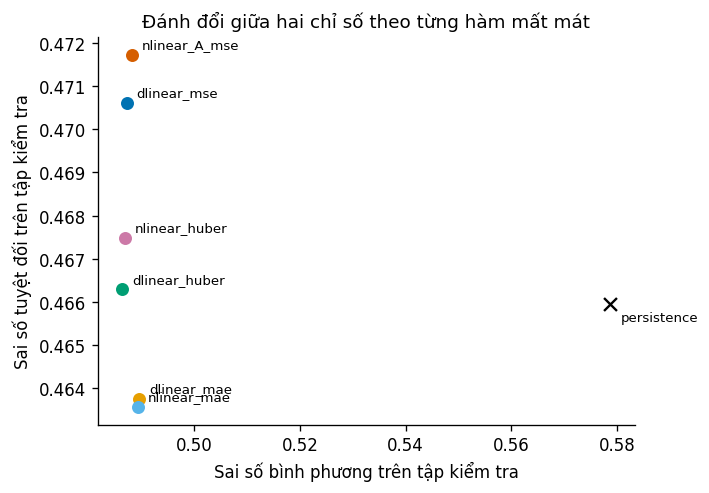

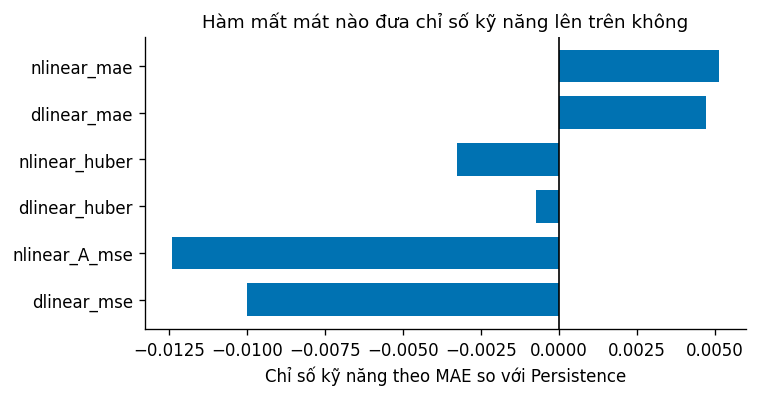

In [10]:
ten_hien = list(tong_hop.keys())
fig, ax = plt.subplots(figsize=(5.8, 4.0))
for i, ten in enumerate(ten_hien):
    d = tong_hop[ten]
    ax.scatter([d["mse"]], [d["mae"]], s=46, color=PALETTE[i % len(PALETTE)], zorder=3)
    ax.annotate(ten, (d["mse"], d["mae"]), textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.scatter([mse_persistence], [mae_persistence], marker="x", s=60, color="black", zorder=4)
ax.annotate("persistence", (mse_persistence, mae_persistence),
            textcoords="offset points", xytext=(6, -10), fontsize=8)
ax.set_xlabel("Sai số bình phương trên tập kiểm tra")
ax.set_ylabel("Sai số tuyệt đối trên tập kiểm tra")
ax.set_title("Đánh đổi giữa hai chỉ số theo từng hàm mất mát")
luu_hinh(fig, "fig16_danh_doi_hai_chi_so.png")

nhan = list(tong_hop.keys())
gia_tri = [tong_hop[k]["ky_nang_mae"] for k in nhan]
fig, ax = plt.subplots(figsize=(6.2, 3.2))
ax.barh(np.arange(len(nhan)), gia_tri, color=PALETTE[0], height=0.7)
ax.axvline(0.0, color="black", linewidth=1.0)
ax.set_yticks(np.arange(len(nhan)))
ax.set_yticklabels(nhan)
ax.set_xlabel("Chỉ số kỹ năng theo MAE so với Persistence")
ax.set_title("Hàm mất mát nào đưa chỉ số kỹ năng lên trên không")
luu_hinh(fig, "fig17_ky_nang_theo_ham_mat_mat.png")

In [11]:
bao_cao = {"kiem_tra_luc": datetime.datetime.now().isoformat(timespec="seconds"),
           "read_tag": READ_TAG, "run_tag": RUN_TAG,
           "huber_delta": HUBER_DELTA, "n_seeds": N_SEEDS,
           "mae_persistence": mae_persistence, "mse_persistence": mse_persistence,
           "tong_hop": tong_hop, "env": ENV}
(RUN_DIR / "W2_ham_mat_mat_huber.json").write_text(
    json.dumps(bao_cao, ensure_ascii=False, indent=2))
print("Đã ghi", RUN_DIR / "W2_ham_mat_mat_huber.json")

Đã ghi /content/drive/MyDrive/AIO2026_Conquer_M4_DLinear_NLinear_Slot4/Output/processed/bo_sung_06_huber/W2_ham_mat_mat_huber.json


## 5. Cách đọc kết quả

- Nếu chỉ số kỹ năng theo MAE chuyển từ âm sang dương khi đổi hàm mất mát, nghịch lý ở mục kết quả tuần 2 đã được giải thích bằng thực nghiệm, không còn là phỏng đoán.
- Nếu đổi hàm mất mát làm tăng sai số bình phương, đó là kết quả bình thường và phải báo cáo đầy đủ. Mỗi hàm mất mát tối ưu đúng chỉ số của nó.
- Kết luận cần viết trong báo cáo: chọn hàm mất mát là một quyết định lâm sàng, không phải một quyết định kỹ thuật thuần. Sai số đuôi quan trọng với cảnh báo sớm, sai số trung vị quan trọng với theo dõi thường quy.